# 2. Working with data in pandas (Ishuset): suggested solution

This is the suggested solution to `02_pandas_ishuset.ipynb`. The task texts are the same as in the exercise notebook. Under each task there is a suggested solution. There are often more correct solutions than the one shown.

You work at **Ishuset**, a small chain of ice cream kiosks with four shops in North Jutland: the original shop in Aalborg and three summer kiosks in Blokhus, Løkken and Skagen. Your manager has sent you an extract from the cash register system for June and July 2026.

Each row in the file is one **sales line**: one product sold in some quantity. If a customer buys, say, a softice and a slushice, that gives two rows.

| Column | Meaning |
| --- | --- |
| `SaleId` | unique number for the sales line |
| `Date` | date of sale |
| `Shop` | which shop the sale took place in |
| `Item` | the product |
| `Quantity` | number of units sold |
| `UnitPrice` | price per unit in DKK |

**How to use the notebook:** Run the cells from top to bottom. A cell is run with Shift+Enter. If something goes wrong, choose Runtime > Run all and start over. You fill in the cells in the exercises yourself.

## Part 1: Load and inspect data

In [1]:
# Import pandas with the usual alias
import pandas as pd

# The address of the data file (in the course's GitHub repository):
DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/ishuset.xlsx"

In [2]:
# Load the data file into a DataFrame named df
df = pd.read_excel(DATA_URL)

A **DataFrame** is the pandas version of a spreadsheet: rows and columns with names. `head()` shows the first 5 rows, so you can see what the data look like. Remember: one row is one sales line.

In [3]:
# Show the first 5 rows
df.head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice
0,2017,2026-06-01,Aalborg C,Softice,2,45
1,2051,2026-06-01,Skagen,Softice,4,45
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38


In [4]:
# How large is the table? shape gives (rows, columns)
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns")

The dataset has 300 rows and 6 columns


`describe()` gives summary statistics for the numeric columns all at once: number of observations (count), mean, standard deviation (std), minimum, quartiles and maximum. The **50%** row is the median.

In [5]:
# Statistical overview of the numeric columns
df.describe()

,SaleId,Date,Quantity,UnitPrice
count,300.000000,300,300.000000,300.000000
mean,2150.500000,2026-07-01 20:48:00,2.533333,48.450000
min,2001.000000,2026-06-01 00:00:00,1.000000,35.000000
25%,2075.750000,2026-06-17 00:00:00,1.000000,45.000000
50%,2150.500000,2026-07-01 12:00:00,3.000000,50.000000
75%,2225.250000,2026-07-17 06:00:00,4.000000,55.000000
max,2300.000000,2026-07-31 00:00:00,4.000000,62.000000
std,86.746758,NaN,1.145978,8.020094


In [6]:
# A single column is selected with df["ColumnName"]. On it you can compute:
print(f"Average quantity per sales line: {df['Quantity'].mean():.2f}")
print(f"Total number of units sold: {df['Quantity'].sum()}")
print(f"Smallest quantity on a sales line: {df['Quantity'].min()}")
print(f"Largest quantity on a sales line: {df['Quantity'].max()}")

Average quantity per sales line: 2.53
Total number of units sold: 760
Smallest quantity on a sales line: 1
Largest quantity on a sales line: 4


For categorical columns (text), an average makes no sense. There you use `value_counts()`, which counts how many times each value occurs. The result is sorted with the most frequent at the top.

In [7]:
# How many sales lines are there for each product?
df["Item"].value_counts()

Item
Waffle 2 scoops    101
Softice             63
Waffle 3 scoops     41
Slushice            38
Milkshake           36
Waffle 1 scoop      21
Name: count, dtype: int64

---
## Exercise 4: Explore the data

Solve the tasks in order. All the patterns you need are in **Part 1** above: find the cell that looks similar, and adapt it. Tasks marked **(extra)** are optional.

The data are already loaded in `df`, but in task 1 you practice the loading yourself.

In [8]:
# === TASK 1: SOLUTION ===
# 1. Load the data file from DATA_URL into a new DataFrame named df2
df2 = pd.read_excel(DATA_URL)

# 2. Show the first 5 rows of df2
df2.head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice
0,2017,2026-06-01,Aalborg C,Softice,2,45
1,2051,2026-06-01,Skagen,Softice,4,45
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38


In [9]:
# === TASK 2: SOLUTION ===
# 1. Compute and show the mean of UnitPrice
print(f"Average unit price: {df['UnitPrice'].mean():.2f} DKK")

# 2. Compute and show the highest UnitPrice
print(f"Highest unit price: {df['UnitPrice'].max()} DKK")

Average unit price: 48.45 DKK
Highest unit price: 62 DKK


In [10]:
# === TASK 3: SOLUTION ===
# Count how many sales lines each shop has (value_counts)
df["Shop"].value_counts()

Shop
Aalborg C    123
Blokhus       78
Løkken        55
Skagen        44
Name: count, dtype: int64

**Answer in words (suggested solution):**

Which shop has the fewest sales lines? **Skagen, 44 sales lines.**

Does that fit the story of Ishuset? **Yes: Aalborg C is the large shop with the most sales lines (123), and the three summer kiosks are lower.**

**Read the `describe()` output from Part 1 (suggested solution):**

1. The median of `Quantity` is **3** (the 50% row).
2. Cheapest item: **35 DKK (Slushice)**. Most expensive item: **62 DKK (Waffle 3 scoops)**. The amounts themselves are read as min and max for UnitPrice; the item names require a look at the data.

In [11]:
# === TASK 4 (extra): SOLUTION ===
# Find the median of UnitPrice with code
print(f"Median of UnitPrice: {df['UnitPrice'].median()} DKK")
# Corresponds to the 50% row for UnitPrice in the describe() output in Part 1

Median of UnitPrice: 50.0 DKK


---
## Part 2: Compute, filter and visualize

In [12]:
# For charts we use matplotlib, which is imported with this alias:
import matplotlib.pyplot as plt

**New column from existing columns.** You write `df["NewName"] = ...` with a calculation on the right-hand side. Here is an example: Ishuset is considering a summer campaign with a 20 percent discount, and the manager wants to see the campaign price for each sales line.

In [13]:
# Create a new column: campaign price with a 20 percent discount
df["CampaignPrice"] = df["UnitPrice"] * 0.8

# Show the first 5 rows, so the new column can be seen
df.head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice,CampaignPrice
0,2017,2026-06-01,Aalborg C,Softice,2,45,36.0
1,2051,2026-06-01,Skagen,Softice,4,45,36.0
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,49.6
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62,49.6
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38,30.4


**Lookup: find one specific row.** `df[df["SaleId"] == 2130]` should be read from the inside out: the condition `df["SaleId"] == 2130` picks out the rows where it is true, and `df[...]` shows exactly those. The data are not sorted by SaleId, so without code you would have to scroll for a long time.

In [14]:
# The manager asks about the sales line with SaleId 2130
df[df["SaleId"] == 2130]

,SaleId,Date,Shop,Item,Quantity,UnitPrice,CampaignPrice
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,49.6


**Filter and compute.** The same pattern as a lookup, but the condition matches many rows. The result is stored under its own name, and you can then compute on it as on any DataFrame.

In [15]:
# All sales lines from the shop in Blokhus
blokhus = df[df["Shop"] == "Blokhus"]

print(f"Number of sales lines in Blokhus: {len(blokhus)}")
print(f"Average quantity per sales line in Blokhus: {blokhus['Quantity'].mean():.2f}")

Number of sales lines in Blokhus: 78
Average quantity per sales line in Blokhus: 2.62


**Histogram: the distribution of a numeric column.** `plt.hist` divides the values into intervals (bins) and counts how many land in each. A chart should always be understandable without explanation: labels on both axes and a title.

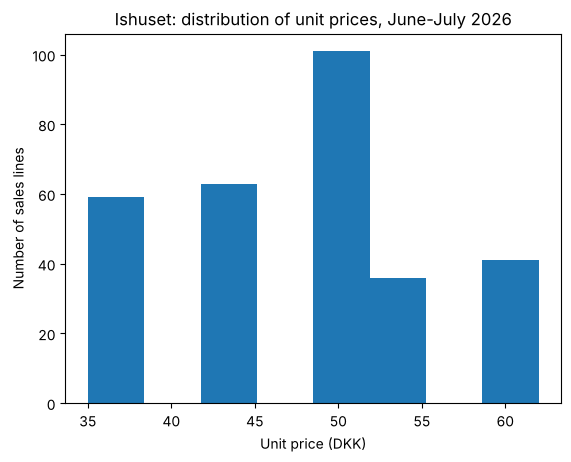

In [16]:
# The distribution of unit prices, 8 intervals
plt.hist(df["UnitPrice"], bins=8)
plt.xlabel("Unit price (DKK)")
plt.ylabel("Number of sales lines")
plt.title("Ishuset: distribution of unit prices, June-July 2026")
plt.show()

**Sort with `sort_values`.** Useful when you want to see the largest or smallest values. `ascending=False` gives descending order.

In [17]:
# The 5 sales lines with the highest unit price
df.sort_values("UnitPrice", ascending=False).head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice,CampaignPrice
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,49.6
294,2043,2026-07-31,Aalborg C,Waffle 3 scoops,2,62,49.6
255,2168,2026-07-24,Aalborg C,Waffle 3 scoops,2,62,49.6
246,2279,2026-07-21,Aalborg C,Waffle 3 scoops,3,62,49.6
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62,49.6


**FOR DEMONSTRATION ONLY: run the cell, and look at the figure.** It shows the revenue per day over the summer. The code uses `groupby`, which you know from Applied Statistics in the 2nd semester; it is not part of the exercises here. Notice the weekend peaks: good ice cream weather and time off at the same time.

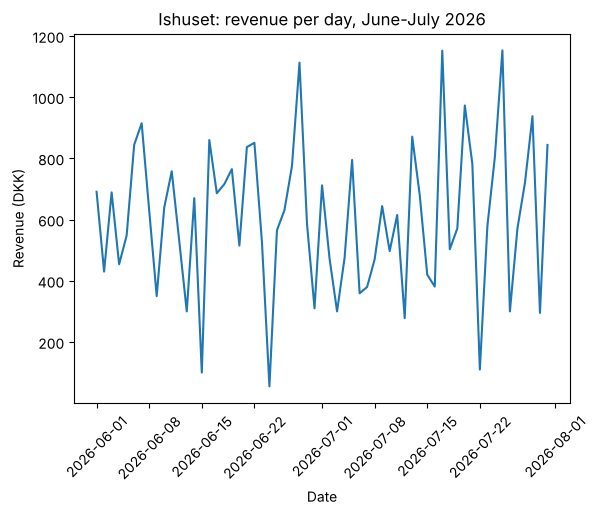

In [18]:
# FOR DEMONSTRATION ONLY (groupby is not part of the exercises here)
revenue_per_day = (df["Quantity"] * df["UnitPrice"]).groupby(df["Date"]).sum()

plt.plot(revenue_per_day.index, revenue_per_day.values)
plt.xlabel("Date")
plt.ylabel("Revenue (DKK)")
plt.title("Ishuset: revenue per day, June-July 2026")
plt.xticks(rotation=45)
plt.show()

---
## Exercise 5: Mini case

Your manager needs a quick overview of the summer sales and has sent four tasks. All the patterns are in **Part 2** above. Tasks marked **(extra)** are optional.

In [19]:
# === TASK 1: SOLUTION ===
# 1. Create a new column in df named Revenue, computed as Quantity times UnitPrice
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# 2. Show the first 5 rows, so the new column can be seen
df.head()

,SaleId,Date,Shop,Item,Quantity,UnitPrice,CampaignPrice,Revenue
0,2017,2026-06-01,Aalborg C,Softice,2,45,36.0,90
1,2051,2026-06-01,Skagen,Softice,4,45,36.0,180
2,2130,2026-06-01,Skagen,Waffle 3 scoops,3,62,49.6,186
3,2148,2026-06-01,Blokhus,Waffle 3 scoops,2,62,49.6,124
4,2189,2026-06-01,Aalborg C,Waffle 1 scoop,2,38,30.4,76


In [20]:
# === TASK 2: SOLUTION ===
# 1. Select the rows where Item is "Softice"
softice = df[df["Item"] == "Softice"]

# 2. Show the sum of Revenue for these rows
print(f"Total revenue for Softice: {softice['Revenue'].sum()} DKK")

# 3. Show the mean of Revenue for these rows
print(f"Average revenue per Softice sales line: {softice['Revenue'].mean():.1f} DKK")

Total revenue for Softice: 6795 DKK
Average revenue per Softice sales line: 107.9 DKK


In [21]:
# === TASK 3: SOLUTION ===
blokhus = df[df["Shop"] == "Blokhus"]
print(f"Blokhus: average revenue per sales line = {blokhus['Revenue'].mean():.1f} DKK")

# The corresponding two lines for Skagen:
skagen = df[df["Shop"] == "Skagen"]
print(f"Skagen: average revenue per sales line = {skagen['Revenue'].mean():.1f} DKK")

Blokhus: average revenue per sales line = 131.0 DKK
Skagen: average revenue per sales line = 123.0 DKK


**Answer in words (suggested solution):** Blokhus sells more per sales line: **131.0 DKK against Skagen's 123.0 DKK.**

**(extra)** All four shops: Blokhus 131.0, Løkken 124.6, Skagen 123.0, Aalborg C 117.9 DKK. The flagship in Aalborg has the most sales lines but the smallest average line. A reasonable suggestion: tourists at the coast buy more and more expensive ice creams per purchase than the city's customers.

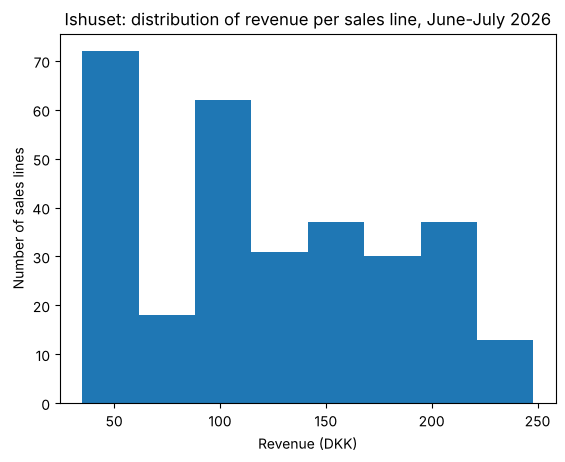

In [22]:
# === TASK 4: SOLUTION ===
plt.hist(df["Revenue"], bins=8)
plt.xlabel("Revenue (DKK)")
plt.ylabel("Number of sales lines")
plt.title("Ishuset: distribution of revenue per sales line, June-July 2026")
plt.show()

**Answer in words (suggested solution):** Example of an answer: Most sales lines are between about 35 and 150 DKK, and only a few large sales lines go above 200 DKK (the distribution is right-skewed). Other wordings that describe where most of the values lie are just as good.

In [23]:
# === TASK 5 (extra): SOLUTION ===
# Show the 10 sales lines with the largest Revenue
df.sort_values("Revenue", ascending=False).head(10)

,SaleId,Date,Shop,Item,Quantity,UnitPrice,CampaignPrice,Revenue
249,2198,2026-07-23,Blokhus,Waffle 3 scoops,4,62,49.6,248
225,2181,2026-07-18,Blokhus,Waffle 3 scoops,4,62,49.6,248
57,2239,2026-06-12,Aalborg C,Waffle 3 scoops,4,62,49.6,248
238,2273,2026-07-20,Aalborg C,Waffle 3 scoops,4,62,49.6,248
180,2084,2026-07-09,Blokhus,Waffle 3 scoops,4,62,49.6,248
105,2032,2026-06-23,Blokhus,Waffle 3 scoops,4,62,49.6,248
198,2169,2026-07-13,Skagen,Waffle 3 scoops,4,62,49.6,248
80,2159,2026-06-18,Blokhus,Waffle 3 scoops,4,62,49.6,248
276,2190,2026-07-27,Aalborg C,Waffle 3 scoops,4,62,49.6,248
19,2092,2026-06-05,Løkken,Waffle 3 scoops,4,62,49.6,248


---
## Summary: what you have just done

The mini case corresponds to the tasks in the practice case (notebook 3):

1. Load and inspect a data file (exercise 4, task 1)
2. Create a computed column (task 1 above)
3. Look up a specific row by SaleId (the pattern from Part 2)
4. Filter and compute a sum and a mean (task 2 above)
5. Histogram with axis labels and a title (task 4 above)

In the practice case you get a **new dataset from a different company**. The column names are not the same as in Ishuset, so always start with `head()`, and use the column names you see there. Feel free to keep this notebook open while you solve the case.